# 02 - Classification Data Preparation

prepares the brain MRI dataset for classification:
1. Reads raw images from `data/raw/` (`Train` and `Val` folders).
2. Uses `data/raw/Val` directly as the **Validation** set.
3. Splits `data/raw/Train` into **Train** (85%) and **Test** (15%) without overlap.
4. Organizes images into standard directory structure: `data/prepared/classification/{train, val, test}/{class_name}/`.
5. Verifies split counts and displays sample images.


In [ ]:
from pathlib import Path
import shutil
import random
import matplotlib.pyplot as plt
from PIL import Image

# Paths setup
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
OUTPUT_DIR = ROOT / "data" / "prepared" / "classification"

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

print(f"Raw data directory:    {RAW_DIR}")
print(f"Output directory:      {OUTPUT_DIR}")


In [2]:
# Check available images in raw data
print("=== RAW IMAGES COUNT ===")
for split in ["Train", "Val"]:
    print(f"\n[{split}]")
    total = 0
    for cls in CLASSES:
        img_folder = RAW_DIR / split / cls / "images"
        count = len(list(img_folder.glob("*.jpg"))) if img_folder.exists() else 0
        total += count
        print(f"  {cls:12}: {count} images")
    print(f"  Total {split}: {total}")


=== RAW IMAGES COUNT ===

[Train]
  Glioma      : 1153 images
  Meningioma  : 1449 images
  No Tumor    : 711 images
  Pituitary   : 1424 images
  Total Train: 4737

[Val]
  Glioma      : 136 images
  Meningioma  : 140 images
  No Tumor    : 100 images
  Pituitary   : 136 images
  Total Val: 512


In [ ]:
# Simple split and copy
random.seed(42)

# Reset output directory
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for split in ["train", "val", "test"]:
    for cls in CLASSES:
        (OUTPUT_DIR / split / cls).mkdir(parents=True, exist_ok=True)

# [1] Copy Val -> val (100%)
for cls in CLASSES:
    val_files = sorted(list((RAW_DIR / "Val" / cls / "images").glob("*.jpg")))
    for f in val_files:
        shutil.copy2(f, OUTPUT_DIR / "val" / cls / f.name)

# [2] Split Train -> train (85%) and test (15%)
for cls in CLASSES:
    train_files = sorted(list((RAW_DIR / "Train" / cls / "images").glob("*.jpg")))
    random.shuffle(train_files)
    
    split_idx = int(0.85 * len(train_files))
    train_split = train_files[:split_idx]
    test_split = train_files[split_idx:]
    
    for f in train_split:
        shutil.copy2(f, OUTPUT_DIR / "train" / cls / f.name)
    for f in test_split:
        shutil.copy2(f, OUTPUT_DIR / "test" / cls / f.name)

print("Data split and copy completed successfully!")


Data split and copy completed successfully!


In [4]:
# Verify prepared split counts
print("=== PREPARED DATASET SUMMARY ===")
header = f"{'Class':15} | {'Train':>8} | {'Val':>8} | {'Test':>8} | {'Total':>8}"
print(header)
print("-" * len(header))

totals = {"train": 0, "val": 0, "test": 0, "all": 0}

for cls in CLASSES:
    n_tr = len(list((OUTPUT_DIR / "train" / cls).glob("*.jpg")))
    n_va = len(list((OUTPUT_DIR / "val" / cls).glob("*.jpg")))
    n_te = len(list((OUTPUT_DIR / "test" / cls).glob("*.jpg")))
    total_cls = n_tr + n_va + n_te
    
    totals["train"] += n_tr
    totals["val"] += n_va
    totals["test"] += n_te
    totals["all"] += total_cls
    
    print(f"{cls:15} | {n_tr:8d} | {n_va:8d} | {n_te:8d} | {total_cls:8d}")

print("-" * len(header))
print(f"{'TOTAL':15} | {totals['train']:8d} | {totals['val']:8d} | {totals['test']:8d} | {totals['all']:8d}")


=== PREPARED DATASET SUMMARY ===
Class           |    Train |      Val |     Test |    Total
-----------------------------------------------------------
Glioma          |      980 |      136 |      173 |     1289
Meningioma      |     1231 |      140 |      218 |     1589
No Tumor        |      604 |      100 |      107 |      811
Pituitary       |     1210 |      136 |      214 |     1560
-----------------------------------------------------------
TOTAL           |     4025 |      512 |      712 |     5249


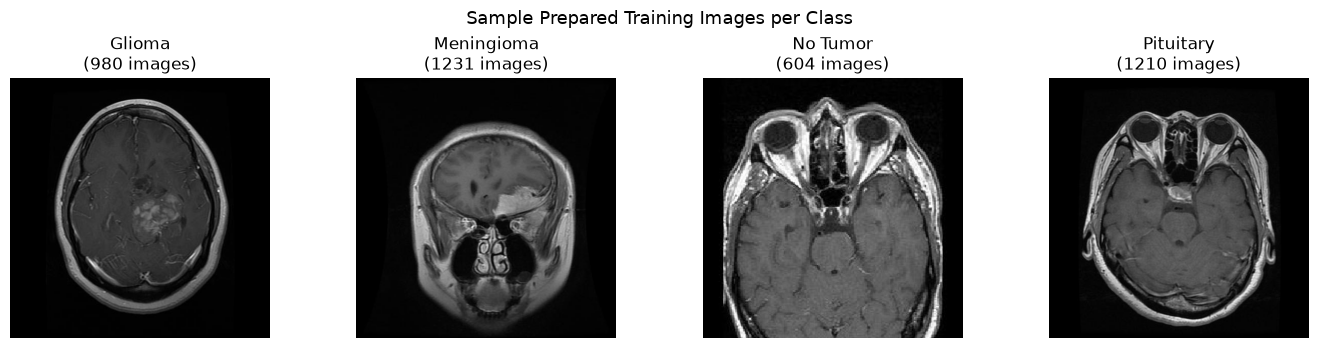

In [5]:
# Visual preview of sample images
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for idx, cls in enumerate(CLASSES):
    sample_files = list((OUTPUT_DIR / "train" / cls).glob("*.jpg"))
    if sample_files:
        img = Image.open(sample_files[0])
        axes[idx].imshow(img, cmap="gray" if img.mode == "L" else None)
        axes[idx].set_title(f"{cls}\n({len(sample_files)} images)")
    axes[idx].axis("off")

plt.suptitle("Sample Prepared Training Images per Class", fontsize=13)
plt.tight_layout()
plt.show()
